# 01 Data understanding

**Question:** what is on disk, and is there anything that would break the train, validation and test split?

**Data:** `data/raw/brain-tumor-mri-dataset/{Training,Testing}`, downloaded 2026-11-21.

**Conclusion:** counts match the publisher and there is no Training/Testing overlap by exact hash, but a perceptual hash finds near duplicates across the two (section 4b). `Training` has exact duplicates, so the validation split is grouped by hash (sections 7 and 9). Image size and color mode differ by class, which is a possible shortcut for a model (section 6).

Cycle 1, Brain Tumor MRI Dataset (Masoud Nickparvar). Protocol: `docs/crisp-dm/02-data-understanding.md`.

This notebook only describes the files on disk. It fits nothing, writes nothing to `data/raw/`, and
produces no preprocessing that training reuses. Every number below comes from running the cells.
Figures are saved to `reports/figures/`.

In [15]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "brain-tumor-mri-dataset"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SPLITS = ["Training", "Testing"]
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
PUBLISHER_CLAIM = {"Training": 1400, "Testing": 400}  # per class, publisher's figure
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}

assert RAW.is_dir(), f"missing {RAW}"

## 1. File inventory

In [16]:
rows = []
for split in SPLITS:
    for cls in CLASSES:
        for p in sorted((RAW / split / cls).iterdir()):
            rows.append(
                {
                    "split": split,
                    "label": cls,
                    "path": p,
                    "suffix": p.suffix.lower(),
                    "bytes": p.stat().st_size,
                }
            )
inv = pd.DataFrame(rows)
print("total files:", len(inv))
print("non-image suffixes:", sorted(set(inv["suffix"]) - IMAGE_SUFFIXES))
print("suffix counts:")
print(inv["suffix"].value_counts().to_string())

total files: 7200
non-image suffixes: []
suffix counts:
suffix
.jpg    7200


## 2. Counts per class against the publisher's claim

In [17]:
counts = inv.groupby(["split", "label"]).size().unstack("label")[CLASSES]
claim = pd.DataFrame({c: PUBLISHER_CLAIM for c in CLASSES})
print(counts.to_string())
print()
print("difference vs publisher claim (disk minus claim):")
print((counts - claim).to_string())
print("total:", int(counts.to_numpy().sum()))

label     glioma  meningioma  notumor  pituitary
split                                           
Testing      400         400      400        400
Training    1400        1400     1400       1400

difference vs publisher claim (disk minus claim):
label     glioma  meningioma  notumor  pituitary
Testing        0           0        0          0
Training       0           0        0          0
total: 7200


## 3. Decoding, size and color mode

In [18]:
def probe(path):
    try:
        with Image.open(path) as im:
            im.verify()
        with Image.open(path) as im:
            w, h = im.size
            return {"ok": True, "width": w, "height": h, "mode": im.mode, "error": ""}
    except Exception as exc:  # report every failure, do not stop
        return {"ok": False, "width": None, "height": None, "mode": None, "error": repr(exc)}


info = pd.DataFrame([probe(p) for p in inv["path"]], index=inv.index)
img = pd.concat([inv, info], axis=1)
print("files that fail to decode:", int((~img["ok"]).sum()))
print(img.loc[~img["ok"], ["split", "label", "path", "error"]].to_string())

files that fail to decode: 0
Empty DataFrame
Columns: [split, label, path, error]
Index: []


In [19]:
ok = img[img["ok"]].copy()
ok["size"] = ok["width"].astype(int).astype(str) + "x" + ok["height"].astype(int).astype(str)
print("color modes by split:")
print(ok.groupby(["split", "mode"]).size().unstack("mode", fill_value=0).to_string())
print()
print("distinct (width, height) pairs:", ok["size"].nunique())
print("most common sizes:")
print(ok.groupby("split")["size"].value_counts().groupby(level=0).head(5).to_string())
print()
print(ok[["width", "height"]].describe().loc[["min", "50%", "max"]].to_string())

color modes by split:
mode         L  P   RGB  RGBA
split                        
Testing    709  0   891     0
Training  2358  1  3238     3

distinct (width, height) pairs: 447
most common sizes:
split     size   
Testing   512x512    1002
          225x225      85
          630x630      21
          227x222      19
          228x221      19
Training  512x512    4012
          225x225     253
          630x630      69
          201x251      40
          236x236      39

      width  height
min   150.0   167.0
50%   512.0   512.0
max  1375.0  1446.0


non-square images: 1533 of 7200
aspect ratio (w/h) min / median / max: [0.64, 1.0, 1.79]

file size in KB by split:
          min   50%    max
split                     
Testing   4.6  20.7  118.7
Training  3.6  21.3  299.3


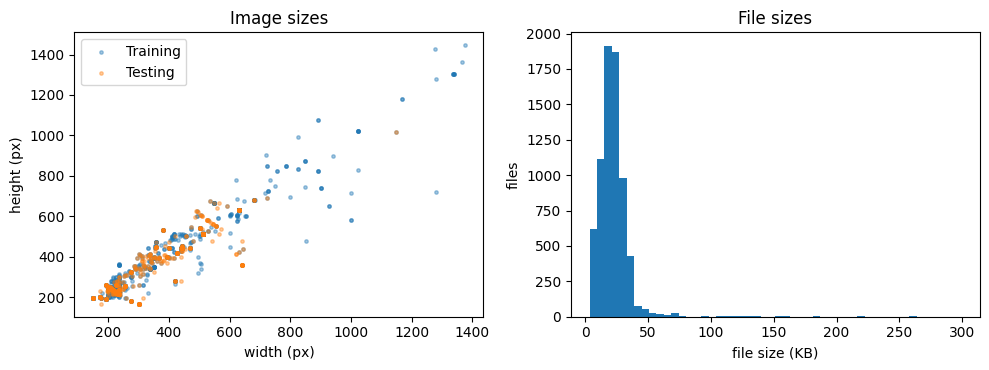

In [ ]:
ok["aspect"] = ok["width"] / ok["height"]
print("non-square images:", int((ok["width"] != ok["height"]).sum()), "of", len(ok))
print(
    "aspect ratio (w/h) min / median / max:",
    ok["aspect"].agg(["min", "median", "max"]).round(2).tolist(),
)
print()
print("file size in KB by split:")
print((ok.groupby("split")["bytes"].describe()[["min", "50%", "max"]] / 1024).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for split, color in zip(SPLITS, ["tab:blue", "tab:orange"], strict=True):
    d = ok[ok["split"] == split]
    axes[0].scatter(d["width"], d["height"], s=6, alpha=0.4, label=split, color=color)
axes[0].set(xlabel="width (px)", ylabel="height (px)", title="Image sizes")
axes[0].legend()
axes[1].hist(ok["bytes"] / 1024, bins=50)
axes[1].set(xlabel="file size (KB)", ylabel="files", title="File sizes")
fig.tight_layout()
# fig.savefig(FIG_DIR / "image-sizes.png", dpi=110)
plt.show()

## 4. Exact duplicates by content hash

SHA-256 of the raw file bytes. This catches byte-identical copies only, not re-encoded or resized
near duplicates.

In [21]:
def sha256(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()


img["sha256"] = [sha256(p) for p in img["path"]]
print("hashed files:", img["sha256"].notna().sum())

hashed files: 7200


In [22]:
print("Within-split duplicates")
for split in SPLITS:
    d = img[img["split"] == split]
    grp = d.groupby("sha256").size()
    dup_hashes = grp[grp > 1]
    print(
        f"  {split}: {len(dup_hashes)} duplicated hashes, "
        f"{int((dup_hashes - 1).sum())} redundant files, "
        f"largest group {int(dup_hashes.max()) if len(dup_hashes) else 0}"
    )

dups = img[img.duplicated("sha256", keep=False)].copy()
red = img[img.duplicated(["split", "sha256"], keep="first")]
print()
print("redundant files per split and class (all but the first copy):")
print(red.groupby(["split", "label"]).size().unstack("label", fill_value=0).to_string())

Within-split duplicates
  Training: 138 duplicated hashes, 171 redundant files, largest group 5
  Testing: 15 duplicated hashes, 16 redundant files, largest group 3

redundant files per split and class (all but the first copy):
label     glioma  meningioma  notumor  pituitary
split                                           
Testing       14           2        0          0
Training       0          14      119         38


In [23]:
train_h = set(img.loc[img["split"] == "Training", "sha256"])
test = img[img["split"] == "Testing"]
overlap = test[test["sha256"].isin(train_h)]
print("Testing files whose hash also appears in Training:", len(overlap))

# Same bytes filed under different class folders would be a label conflict.
n_labels = img.groupby("sha256")["label"].nunique()
conflicts = n_labels[n_labels > 1]
print("hashes filed under more than one class:", len(conflicts))
print(
    dups[dups["sha256"].isin(conflicts.index)]
    .sort_values("sha256")[["split", "label", "path"]]
    .to_string()
)

Testing files whose hash also appears in Training: 0
hashes filed under more than one class: 0
Empty DataFrame
Columns: [split, label, path]
Index: []


In [24]:
groups = (
    img.groupby(["split", "sha256"]).agg(n=("path", "size"), label=("label", "first")).reset_index()
)
multi = groups[groups["n"] > 1]
print("duplicate groups by size (files per hash):")
print(multi.groupby(["split", "n"]).size().unstack("split", fill_value=0).to_string())
print()
print("duplicate groups by class:")
print(multi.groupby(["split", "label"]).size().unstack("label", fill_value=0).to_string())
print()
share = img.assign(in_group=img.duplicated(["split", "sha256"], keep=False))
print("share of files that belong to a duplicate group:")
print(share.groupby("split")["in_group"].mean().round(3).to_string())

# Show the largest Training group (relative paths only).
big = multi[multi["split"] == "Training"].nlargest(1, "n").iloc[0]
members = img[(img["split"] == "Training") & (img["sha256"] == big["sha256"])]
print()
print(f"largest Training group: {int(big['n'])} files, class {big['label']}")
print(members["path"].map(lambda p: p.relative_to(RAW).as_posix()).to_string(index=False))

duplicate groups by size (files per hash):
split  Testing  Training
n                       
2           14       110
3            1        24
4            0         3
5            0         1

duplicate groups by class:
label     glioma  meningioma  notumor  pituitary
split                                           
Testing       13           2        0          0
Training       0          13       97         28

share of files that belong to a duplicate group:
split
Testing     0.019
Training    0.055

largest Training group: 5 files, class notumor
 Training/notumor/Tr-no_112.jpg
Training/notumor/Tr-no_1178.jpg
Training/notumor/Tr-no_1265.jpg
 Training/notumor/Tr-no_308.jpg
 Training/notumor/Tr-no_494.jpg


## 4b. Near duplicates by perceptual hash

Section 4 only sees byte-identical files. A re-saved or resized copy has different bytes, so it
passes that check. This section looks for those with a difference hash (dHash): grayscale, resize
to 9x8, one bit per left-to-right brightness step, 64 bits. Two images are candidates when their
Hamming distance is 0. Because MRI slices look alike, a candidate is only **confirmed** when the
Pearson correlation of the two 64x64 grayscale copies is at least 0.95. The threshold sits far above
the 95th percentile of random same-class pairs (printed below). This is descriptive: nothing is fitted and
no result here is reused by training.

In [ ]:
def dhash(path, side=8):
    with Image.open(path) as im:
        a = np.asarray(
            im.convert("L").resize((side + 1, side), Image.Resampling.LANCZOS), dtype=np.int16
        )
    return int(np.packbits((a[:, 1:] > a[:, :-1]).ravel()).view(">u8")[0])


POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def hamming(h, others):
    x = np.bitwise_xor(others, np.uint64(h)).view(np.uint8).reshape(-1, 8)
    return POPCOUNT[x].sum(axis=1).astype(int)


def gray64(path, side=64):
    with Image.open(path) as im:
        return np.asarray(
            im.convert("L").resize((side, side), Image.Resampling.LANCZOS), np.float32
        )


def corr(a, b):
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-9))


img["dhash"] = [dhash(p) for p in img["path"]]
trn = img[img["split"] == "Training"].reset_index(drop=True)
tst = img[img["split"] == "Testing"].reset_index(drop=True)
tr_h = trn["dhash"].to_numpy(dtype=np.uint64)
tr_sha = trn["sha256"].to_numpy()

# Testing -> nearest Training image.
nn_d, nn_j = [], []
for h in tst["dhash"]:
    d = hamming(h, tr_h)
    nn_j.append(int(d.argmin()))
    nn_d.append(int(d.min()))
tst["nn_dist"], tst["nn_idx"] = nn_d, nn_j

# Training -> nearest other Training image with different bytes (exact copies: section 4).
w_d, w_j = [], []
for i, h in enumerate(tr_h):
    d = hamming(h, tr_h)
    d[tr_sha == tr_sha[i]] = 99
    w_j.append(int(d.argmin()))
    w_d.append(int(d.min()))
trn["nn_dist"], trn["nn_idx"] = w_d, w_j

print("Testing -> nearest Training, dHash distance (first 6 values):")
print(tst["nn_dist"].value_counts().sort_index().head(6).to_string())
print()
print("Training -> nearest other Training file, different bytes, dHash distance (first 6):")
print(trn["nn_dist"].value_counts().sort_index().head(6).to_string())

In [ ]:
rng = np.random.default_rng(SEED)
base = [
    corr(
        gray64(tst["path"][i]),
        gray64(
            trn[trn["label"] == tst["label"][i]]["path"]
            .sample(1, random_state=int(rng.integers(1 << 31)))
            .iloc[0]
        ),
    )
    for i in range(0, len(tst), 4)
]
print(
    f"reference, random same-class Testing/Training pairs (n={len(base)}): "
    f"median {np.median(base):.2f}, 95th pct {np.percentile(base, 95):.2f}, max {max(base):.2f}"
)

NEAR_CORR = 0.95
c_te = tst[tst["nn_dist"] == 0].copy()
c_te["corr"] = [corr(gray64(r.path), gray64(trn["path"][r.nn_idx])) for r in c_te.itertuples()]
c_te["confirmed"] = c_te["corr"] >= NEAR_CORR
c_te["same_label"] = [
    trn["label"][j] == lab for j, lab in zip(c_te["nn_idx"], c_te["label"], strict=True)
]

c_tr = trn[trn["nn_dist"] == 0].copy()
c_tr["corr"] = [corr(gray64(r.path), gray64(trn["path"][r.nn_idx])) for r in c_tr.itertuples()]
c_tr["confirmed"] = c_tr["corr"] >= NEAR_CORR

print()
print(
    f"Testing images with a dHash-0 Training neighbour: {len(c_te)}, "
    f"confirmed (corr >= {NEAR_CORR}): {int(c_te['confirmed'].sum())}, "
    f"same label: {int(c_te['same_label'].sum())}"
)
print(f"  share of Testing: {c_te['confirmed'].sum() / len(tst):.3f}")
print("  confirmed per class:")
print(c_te[c_te["confirmed"]].groupby("label").size().reindex(CLASSES, fill_value=0).to_string())
print()
print(
    f"Training images with a dHash-0 neighbour of different bytes: {len(c_tr)}, "
    f"confirmed: {int(c_tr['confirmed'].sum())} "
    f"({c_tr['confirmed'].sum() / len(trn):.3f} of Training)"
)
print("  confirmed per class:")
print(c_tr[c_tr["confirmed"]].groupby("label").size().reindex(CLASSES, fill_value=0).to_string())

show = pd.concat(
    [
        c_te[c_te["confirmed"] & (c_te["label"] == c)].sample(1, random_state=SEED)
        for c in CLASSES
        if ((c_te["confirmed"]) & (c_te["label"] == c)).any()
    ]
)
fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 4.6))
for k, r in enumerate(show.itertuples()):
    axes[0, k].imshow(gray64(r.path, 256), cmap="gray")
    axes[1, k].imshow(gray64(trn["path"][r.nn_idx], 256), cmap="gray")
    axes[0, k].set_title(f"{r.label}  r={r.corr:.2f}", fontsize=8)
    axes[0, k].axis("off")
    axes[1, k].axis("off")
axes[0, 0].text(
    -0.05,
    0.5,
    "Testing",
    transform=axes[0, 0].transAxes,
    rotation=90,
    ha="right",
    va="center",
    fontsize=8,
)
axes[1, 0].text(
    -0.05,
    0.5,
    "Training",
    transform=axes[1, 0].transAxes,
    rotation=90,
    ha="right",
    va="center",
    fontsize=8,
)
fig.tight_layout()
# fig.savefig(FIG_DIR / "near-duplicates-test-vs-train.png", dpi=110)
plt.show()

## 5. Sample images

Five random `Training` images per class (seed 42), shown in grayscale for a visual sanity check only.
They are not used for any statistic.

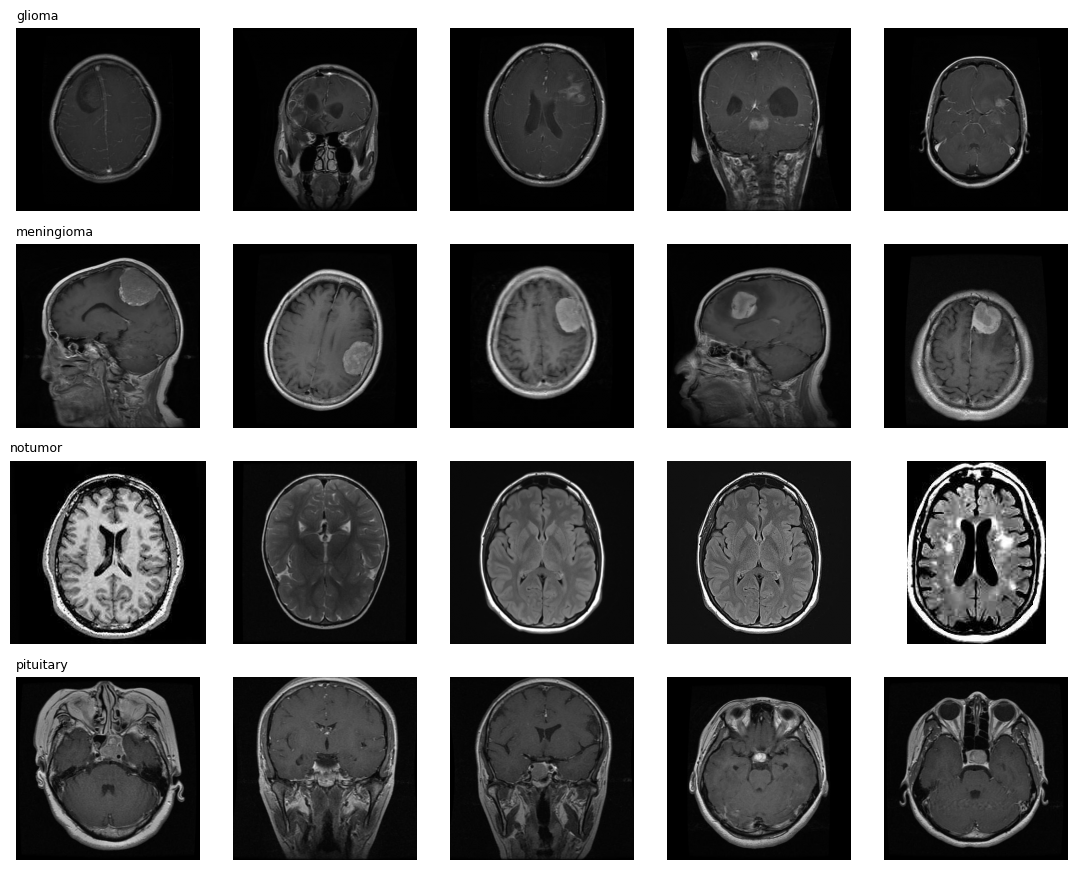

In [ ]:
rng = np.random.default_rng(SEED)
n_show = 5
fig, axes = plt.subplots(len(CLASSES), n_show, figsize=(2.2 * n_show, 2.2 * len(CLASSES)))
for row, cls in enumerate(CLASSES):
    pool = img[(img["split"] == "Training") & (img["label"] == cls)]["path"].tolist()
    for col, i in enumerate(rng.choice(len(pool), size=n_show, replace=False)):
        with Image.open(pool[i]) as im:
            axes[row, col].imshow(im.convert("L"), cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(cls, loc="left", fontsize=9)
fig.tight_layout()
# fig.savefig(FIG_DIR / "samples-per-class.png", dpi=110)
plt.show()

## 6. Per-class descriptives

Do image size, color mode, file size or brightness differ by class? If so, a model could learn that
shortcut instead of the tumor. The first table uses file metadata for both splits. The pixel table
uses `Training` only, at 64x64 grayscale, and is descriptive: it is not reused as a scaling statistic.

In [26]:
ok["is_512"] = (ok["width"] == 512) & (ok["height"] == 512)
ok["is_gray"] = ok["mode"] == "L"
comp = (
    ok.groupby(["split", "label"])
    .agg(
        files=("path", "size"),
        share_512=("is_512", "mean"),
        share_gray_mode=("is_gray", "mean"),
        median_width=("width", "median"),
        median_kb=("bytes", lambda s: s.median() / 1024),
    )
    .round(3)
)
print("file-level metadata per split and class:")
print(comp.to_string())

file-level metadata per split and class:
                     files  share_512  share_gray_mode  median_width  median_kb
split    label                                                                 
Testing  glioma        400      0.810            0.565         512.0     20.173
         meningioma    400      0.708            0.385         512.0     20.158
         notumor       400      0.008            0.015         227.0      9.617
         pituitary     400      0.980            0.808         512.0     25.601
Training glioma       1400      1.000            0.838         512.0     18.508
         meningioma   1400      0.905            0.396         512.0     21.809
         notumor      1400      0.012            0.016         230.0     13.126
         pituitary    1400      0.949            0.434         512.0     28.543


per-image grayscale intensity at 64x64, Training only (mean and spread across images):
             mean           std        dark_share       
             mean    std   mean    std       mean    std
label                                                   
glioma      0.130  0.034  0.143  0.022      0.510  0.103
meningioma  0.170  0.054  0.175  0.030      0.470  0.134
notumor     0.242  0.083  0.215  0.057      0.331  0.185
pituitary   0.194  0.035  0.153  0.020      0.321  0.110


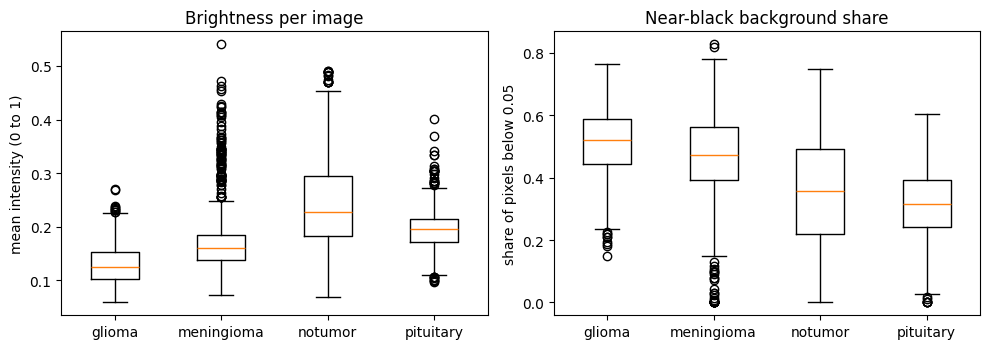

In [ ]:
def pixel_summary(path, side=64):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((side, side)), dtype=np.float32) / 255.0
    return {"mean": a.mean(), "std": a.std(), "dark_share": (a < 0.05).mean()}


tr_all = img[(img["split"] == "Training") & img["ok"]]
pix = pd.DataFrame([pixel_summary(p) for p in tr_all["path"]], index=tr_all.index)
tr_pix = pd.concat([tr_all[["label"]], pix], axis=1)

summary = (
    tr_pix.groupby("label")[["mean", "std", "dark_share"]]
    .agg(["mean", "std"])
    .loc[CLASSES]
    .round(3)
)
print("per-image grayscale intensity at 64x64, Training only (mean and spread across images):")
print(summary.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].boxplot([tr_pix.loc[tr_pix["label"] == c, "mean"] for c in CLASSES], tick_labels=CLASSES)
axes[0].set(ylabel="mean intensity (0 to 1)", title="Brightness per image")
axes[1].boxplot(
    [tr_pix.loc[tr_pix["label"] == c, "dark_share"] for c in CLASSES], tick_labels=CLASSES
)
axes[1].set(ylabel="share of pixels below 0.05", title="Near-black background share")
fig.tight_layout()
# fig.savefig(FIG_DIR / "intensity-per-class.png", dpi=110)
plt.show()

## 7. Dry run of the grouped split

This only checks that the agreed rule is feasible and shows what it would change. It is held in memory:
no indices are written and nothing here is reused by training. The real split lives in
`brain_tumor_ai/preparation/` and writes its indices under `data/interim/`. It uses no pixel values,
only paths, labels and hashes.

In [28]:
tr = img[img["split"] == "Training"].reset_index(drop=True)

# Plain stratified random split, ignoring duplicates.
idx = np.arange(len(tr))
naive_tr, naive_va = train_test_split(idx, test_size=0.2, stratify=tr["label"], random_state=SEED)
naive_shared = set(tr.loc[naive_tr, "sha256"]) & set(tr.loc[naive_va, "sha256"])

# Stratified split grouped by hash. One of five folds is about 20 percent.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
grp_tr, grp_va = next(sgkf.split(tr, tr["label"], groups=tr["sha256"]))
grp_shared = set(tr.loc[grp_tr, "sha256"]) & set(tr.loc[grp_va, "sha256"])

print("hashes present on both sides of the split:")
print("  plain stratified split :", len(naive_shared))
print("  grouped by hash        :", len(grp_shared))
print()
print("grouped split, files per class:")
sizes = pd.DataFrame(
    {
        "train": tr.loc[grp_tr, "label"].value_counts(),
        "validation": tr.loc[grp_va, "label"].value_counts(),
    }
).loc[CLASSES]
sizes["validation_share"] = (sizes["validation"] / (sizes["train"] + sizes["validation"])).round(3)
print(sizes.to_string())
print("overall validation share:", round(len(grp_va) / len(tr), 3))
assert len(grp_shared) == 0
assert len(set(grp_tr) & set(grp_va)) == 0

hashes present on both sides of the split:
  plain stratified split : 56
  grouped by hash        : 0

grouped split, files per class:
            train  validation  validation_share
label                                          
glioma       1120         280               0.2
meningioma   1120         280               0.2
notumor      1120         280               0.2
pituitary    1120         280               0.2
overall validation share: 0.2


## 8. Preprocessing prototype (exploratory)

First computer-vision pipeline for the baseline image contract: intensity slicing, filtering,
histogram equalization, thresholding, and a brain crop. It is a prototype in this notebook. Once it
is accepted it moves into `brain_tumor_ai/preparation/` with tests.

Leakage discipline:

- The split comes first. Every image used below comes from the **train side** of the grouped split of
  section 7. Validation and `Testing` images are not opened here.
- Every step works on one image at a time with constants fixed by eye. Nothing is estimated from the
  data (no mean, no standard deviation, no learned equalization table), so nothing can leak.

Grad-CAM readiness (planned heatmap of where the model looks): `preprocess` returns the exact
128x128 image the model will see (`display`, which is also the array to overlay a heatmap on), the
tensor `model_input` with shape (128, 128, 1) in [0, 1], and the square `crop_box` in original pixel
coordinates. `heatmap_to_original` maps a heatmap back onto the untouched file. Geometry is never
distorted (square crop, no stretch), so a heatmap lines up with the anatomy.

In [29]:
import time

import cv2

CFG = {
    "mask_blur": 7,  # Gaussian kernel before Otsu on the head mask
    "mask_min_share": 0.02,  # smaller masks count as a failure (full-image fallback)
    "crop_margin": 0.06,  # extra border around the head box, as a fraction of its side
    "median_ksize": 3,  # light denoising that keeps edges
    "clahe_clip": 2.0,
    "clahe_tiles": 8,
    "side": 128,  # baseline image contract
}
SLICE_RANGE = (90, 200)  # gray-level window highlighted by intensity slicing


def load_gray(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if g is None:
        raise ValueError(f"cannot read {path}")
    return g


def intensity_slice(gray, lo, hi, background=0.3):
    """Gray-level slicing: keep the window [lo, hi] at full brightness, dim everything else."""
    inside = (gray >= lo) & (gray <= hi)
    return np.where(inside, 255, (gray * background)).astype(np.uint8)


def bit_plane(gray, k):
    return ((gray >> k) & 1).astype(np.uint8) * 255


def brain_mask(gray, blur=7, min_share=0.02):
    """Head mask: Gaussian blur, Otsu threshold, open/close, largest connected component."""
    sm = cv2.GaussianBlur(gray, (blur, blur), 0)
    _, bw = cv2.threshold(sm, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, k)
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, k)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
    if n <= 1:
        return None
    largest = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    mask = (labels == largest).astype(np.uint8) * 255
    return mask if (mask > 0).mean() >= min_share else None


def square_box(mask, margin):
    ys, xs = np.nonzero(mask)
    x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
    side = int(round(max(x1 - x0, y1 - y0) * (1 + 2 * margin)))
    bx0 = int(round((x0 + x1) / 2 - side / 2))
    by0 = int(round((y0 + y1) / 2 - side / 2))
    return bx0, by0, bx0 + side, by0 + side


def full_image_box(shape):
    h, w = shape
    s = max(h, w)
    bx0, by0 = w // 2 - s // 2, h // 2 - s // 2
    return bx0, by0, bx0 + s, by0 + s


def crop_square(gray, box):
    """Crop a square box in original coordinates, padding with black where it leaves the image."""
    x0, y0, x1, y1 = box
    h, w = gray.shape
    pl, pt, pr, pb = max(0, -x0), max(0, -y0), max(0, x1 - w), max(0, y1 - h)
    padded = cv2.copyMakeBorder(gray, pt, pb, pl, pr, cv2.BORDER_CONSTANT, value=0)
    return padded[y0 + pt : y1 + pt, x0 + pl : x1 + pl]


def preprocess(path, cfg=CFG):
    gray = load_gray(path)
    mask = brain_mask(gray, cfg["mask_blur"], cfg["mask_min_share"])
    fallback = mask is None
    box = full_image_box(gray.shape) if fallback else square_box(mask, cfg["crop_margin"])
    crop = crop_square(gray, box)
    den = cv2.medianBlur(crop, cfg["median_ksize"])
    clahe = cv2.createCLAHE(clipLimit=cfg["clahe_clip"], tileGridSize=(cfg["clahe_tiles"],) * 2)
    eq = clahe.apply(den)
    display = cv2.resize(eq, (cfg["side"],) * 2, interpolation=cv2.INTER_AREA)
    return {
        "display": display,
        "model_input": (display.astype(np.float32) / 255.0)[..., None],
        "crop_box": box,
        "original_shape": gray.shape,
        "fallback": fallback,
        "mask": mask,
        "raw_mean": float(gray.mean() / 255.0),
    }


def heatmap_to_original(heatmap, crop_box, original_shape):
    """Place a model-space heatmap back on the original image grid (for Grad-CAM later)."""
    x0, y0, x1, y1 = crop_box
    big = cv2.resize(heatmap.astype(np.float32), (x1 - x0, y1 - y0), interpolation=cv2.INTER_LINEAR)
    h, w = original_shape
    out = np.zeros((h, w), np.float32)
    sx0, sy0, sx1, sy1 = max(0, x0), max(0, y0), min(w, x1), min(h, y1)
    out[sy0:sy1, sx0:sx1] = big[sy0 - y0 : sy1 - y0, sx0 - x0 : sx1 - x0]
    return out


# Train side of the grouped split from section 7. Nothing else is opened in this section.
tr_side = tr.loc[grp_tr]
pick = {
    c: tr_side[tr_side["label"] == c].sample(1, random_state=SEED)["path"].iloc[0] for c in CLASSES
}
print("example images (train side only):")
for c, p in pick.items():
    print(f"  {c:11s} {p.relative_to(RAW).as_posix()}")

example images (train side only):
  glioma      Training/glioma/Tr-gl_1280.jpg
  meningioma  Training/meningioma/Tr-me_1186.jpg
  notumor     Training/notumor/Tr-no_128.jpg
  pituitary   Training/pituitary/Tr-pi_1278.jpg


### 8a. Filters and histogram equalization

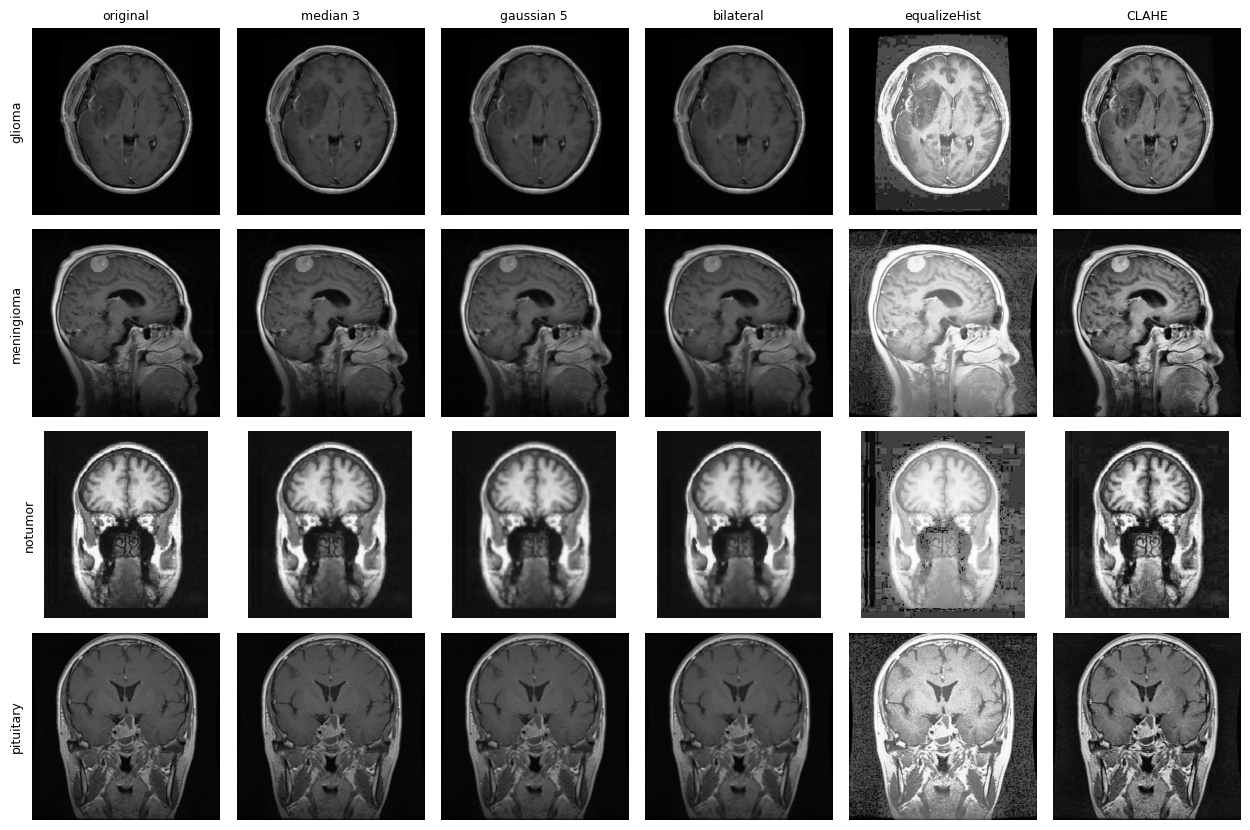

In [ ]:
def show_grid(columns, fname, title_row=True):
    fig, axes = plt.subplots(
        len(CLASSES), len(columns), figsize=(2.1 * len(columns), 2.1 * len(CLASSES))
    )
    for r, cls in enumerate(CLASSES):
        g = load_gray(pick[cls])
        for c, (name, fn) in enumerate(columns):
            axes[r, c].imshow(fn(g), cmap="gray", vmin=0, vmax=255)
            axes[r, c].axis("off")
            if r == 0 and title_row:
                axes[r, c].set_title(name, fontsize=9)
        axes[r, 0].text(
            -0.05,
            0.5,
            cls,
            transform=axes[r, 0].transAxes,
            rotation=90,
            ha="right",
            va="center",
            fontsize=9,
        )
    fig.tight_layout()
    # fig.savefig(FIG_DIR / fname, dpi=110)
    plt.show()


clahe = cv2.createCLAHE(clipLimit=CFG["clahe_clip"], tileGridSize=(CFG["clahe_tiles"],) * 2)
show_grid(
    [
        ("original", lambda g: g),
        ("median 3", lambda g: cv2.medianBlur(g, 3)),
        ("gaussian 5", lambda g: cv2.GaussianBlur(g, (5, 5), 0)),
        ("bilateral", lambda g: cv2.bilateralFilter(g, 7, 40, 5)),
        ("equalizeHist", cv2.equalizeHist),
        ("CLAHE", clahe.apply),
    ],
    "preproc-filters-equalization.png",
)

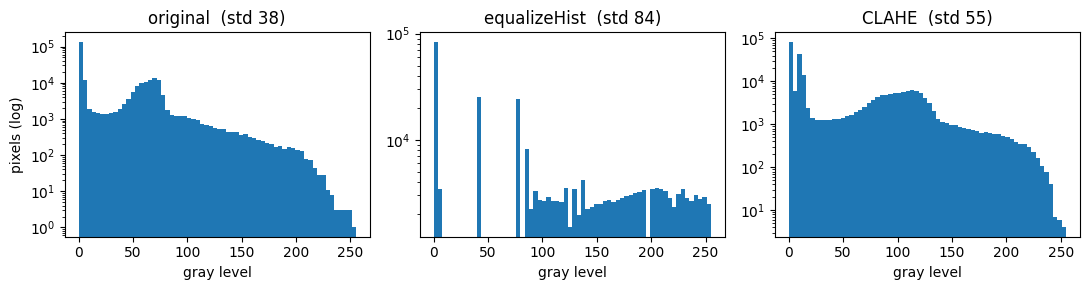

share of pixels at gray level 0 (background) - original / equalizeHist / CLAHE: [0.321, 0.321, 0.0]


In [ ]:
g = load_gray(pick["glioma"])
variants = {"original": g, "equalizeHist": cv2.equalizeHist(g), "CLAHE": clahe.apply(g)}
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, (name, v) in zip(axes, variants.items(), strict=True):
    ax.hist(v.ravel(), bins=64, range=(0, 255), log=True)
    ax.set(title=f"{name}  (std {v.std():.0f})", xlabel="gray level")
axes[0].set_ylabel("pixels (log)")
fig.tight_layout()
# fig.savefig(FIG_DIR / "preproc-histograms.png", dpi=110)
plt.show()
print(
    "share of pixels at gray level 0 (background) - original / equalizeHist / CLAHE:",
    [round(float((v == 0).mean()), 3) for v in variants.values()],
)

### 8b. Intensity slicing and thresholding

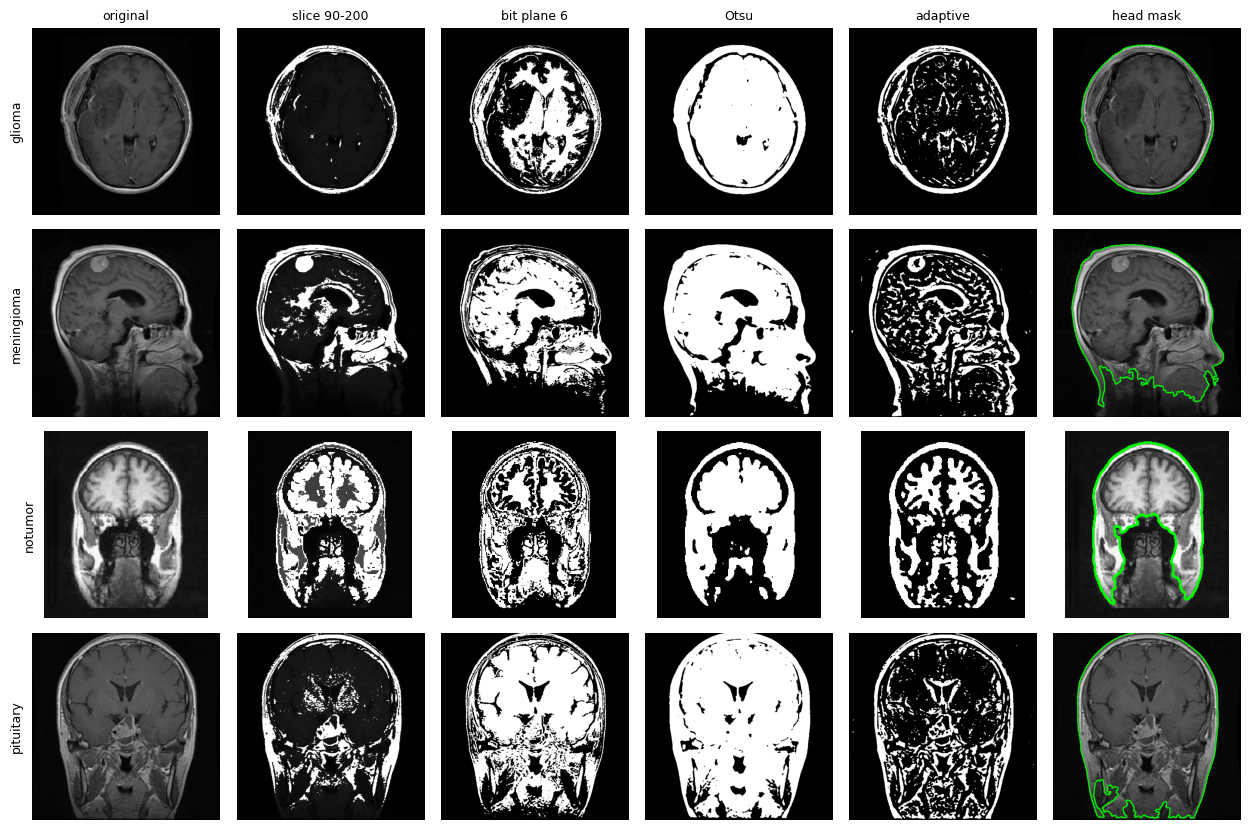

In [34]:
def mask_outline(g):
    m = brain_mask(g)
    rgb = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
    if m is not None:
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(rgb, cnts, -1, (0, 255, 0), 2)
    return cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)


show_grid(
    [
        ("original", lambda g: g),
        (f"slice {SLICE_RANGE[0]}-{SLICE_RANGE[1]}", lambda g: intensity_slice(g, *SLICE_RANGE)),
        ("bit plane 6", lambda g: bit_plane(g, 6)),
        (
            "Otsu",
            lambda g: cv2.threshold(
                cv2.GaussianBlur(g, (7, 7), 0), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
            )[1],
        ),
        (
            "adaptive",
            lambda g: cv2.adaptiveThreshold(
                cv2.GaussianBlur(g, (5, 5), 0),
                255,
                cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                cv2.THRESH_BINARY,
                51,
                -5,
            ),
        ),
        ("head mask", lambda g: mask_outline(g)),
    ],
    "preproc-slicing-threshold.png",
)

### 8c. First pipeline

`preprocess`: grayscale read, head mask (Gaussian, Otsu, morphology, largest component), square crop
with a margin, median 3, CLAHE (clip 2.0, 8x8 tiles), resize to 128x128 with area interpolation,
divide by 255. The crop removes the size cue and the black border. It does not remove brightness or
acquisition differences between classes.

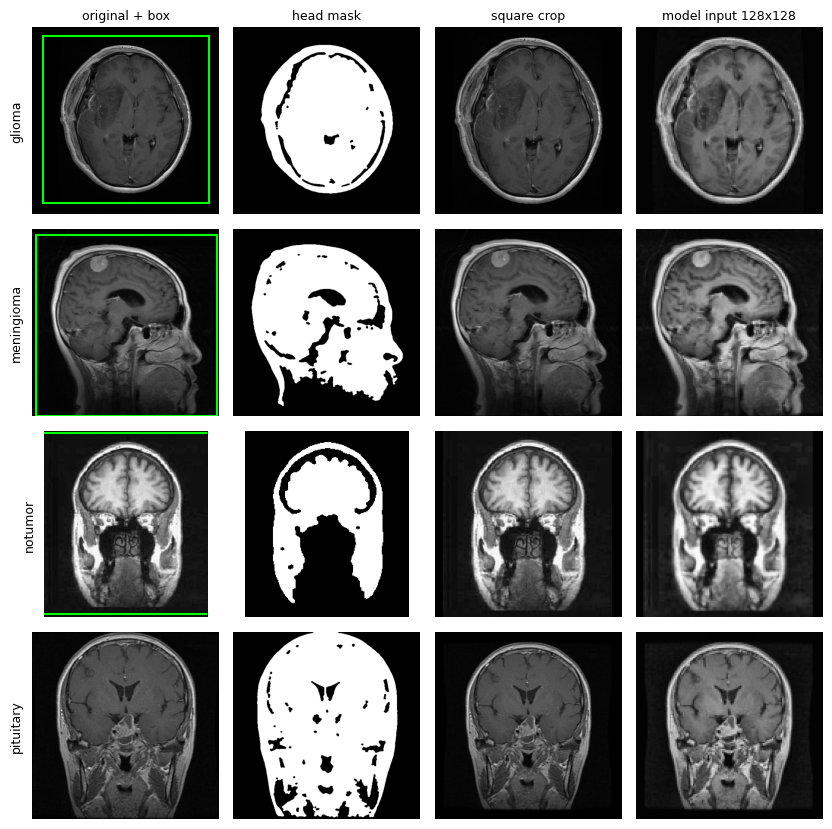

model_input: (128, 128, 1) float32 min/max 0.007843137718737125 0.9058823585510254
deterministic: yes (two runs give identical arrays)


In [ ]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(8.4, 2.1 * len(CLASSES)))
for r, cls in enumerate(CLASSES):
    res = preprocess(pick[cls])
    g = load_gray(pick[cls])
    x0, y0, x1, y1 = res["crop_box"]
    axes[r, 0].imshow(g, cmap="gray")
    axes[r, 0].add_patch(
        plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", lw=1.5)
    )
    axes[r, 1].imshow(res["mask"] if res["mask"] is not None else np.zeros_like(g), cmap="gray")
    axes[r, 2].imshow(crop_square(g, res["crop_box"]), cmap="gray")
    axes[r, 3].imshow(res["display"], cmap="gray", vmin=0, vmax=255)
    for c in range(4):
        axes[r, c].axis("off")
    axes[r, 0].text(
        -0.05,
        0.5,
        cls,
        transform=axes[r, 0].transAxes,
        rotation=90,
        ha="right",
        va="center",
        fontsize=9,
    )
for c, name in enumerate(["original + box", "head mask", "square crop", "model input 128x128"]):
    axes[0, c].set_title(name, fontsize=9)
fig.tight_layout()
# fig.savefig(FIG_DIR / "preproc-pipeline.png", dpi=110)
plt.show()

res = preprocess(pick["glioma"])
print(
    "model_input:",
    res["model_input"].shape,
    res["model_input"].dtype,
    "min/max",
    float(res["model_input"].min()),
    float(res["model_input"].max()),
)
assert res["model_input"].shape == (128, 128, 1)
assert 0.0 <= res["model_input"].min() and res["model_input"].max() <= 1.0
assert np.array_equal(preprocess(pick["glioma"])["display"], res["display"]), (
    "pipeline must be deterministic"
)
print("deterministic: yes (two runs give identical arrays)")

### 8d. Heatmap geometry check (for the later Grad-CAM step)

A model-space heatmap has to land on the right anatomy in the original file. This checks the mapping
with a synthetic heatmap that is hot at one known point. No model exists yet.

In [ ]:
res = preprocess(pick["meningioma"])
hm = np.zeros((16, 16), np.float32)
hm[8, 8] = 1.0  # a hot cell at the centre of a 16x16 map, as a last conv layer would give
big = heatmap_to_original(hm, res["crop_box"], res["original_shape"])
y, x = np.unravel_index(np.argmax(big), big.shape)
x0, y0, x1, y1 = res["crop_box"]
cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
print("crop_box:", res["crop_box"], " original shape:", res["original_shape"])
print(f"hot cell lands at (x={x}, y={y}); crop centre is (x={cx:.0f}, y={cy:.0f})")
assert abs(x - cx) <= (x1 - x0) / 16 + 1 and abs(y - cy) <= (y1 - y0) / 16 + 1
ones = heatmap_to_original(np.ones((16, 16), np.float32), res["crop_box"], res["original_shape"])
inside = np.zeros_like(ones, bool)
inside[max(0, y0) : min(ones.shape[0], y1), max(0, x0) : min(ones.shape[1], x1)] = True
assert np.allclose(ones[inside], 1.0) and np.allclose(ones[~inside], 0.0)
print("heatmap fills exactly the crop box and nothing outside it: ok")

crop_box: (10, 16, 506, 512)  original shape: (512, 512)
hot cell lands at (x=273, y=279); crop centre is (x=258, y=264)
heatmap fills exactly the crop box and nothing outside it: ok


### 8e. Effect of the pipeline on the train side

In [ ]:
t0 = time.perf_counter()
recs = []
for path, label in zip(tr_side["path"], tr_side["label"], strict=True):
    r = preprocess(path)
    x0, y0, x1, y1 = r["crop_box"]
    h, w = r["original_shape"]
    recs.append(
        {
            "label": label,
            "raw_mean": r["raw_mean"],
            "mean_after": float(r["model_input"].mean()),
            "crop_side_share": (x1 - x0) / max(h, w),
            "fallback": r["fallback"],
        }
    )
elapsed = time.perf_counter() - t0
eff = pd.DataFrame(recs)
print(f"{len(eff)} train-side images in {elapsed:.1f} s ({1000 * elapsed / len(eff):.1f} ms each)")
print("mask failures (full-image fallback):", int(eff["fallback"].sum()))
table = (
    eff.groupby("label")
    .agg(
        n=("label", "size"),
        fallbacks=("fallback", "sum"),
        crop_side_share=("crop_side_share", "median"),
        mean_before=("raw_mean", "mean"),
        mean_after=("mean_after", "mean"),
        std_after=("mean_after", "std"),
    )
    .loc[CLASSES]
    .round(3)
)
print(table.to_string())

4480 train-side images in 23.4 s (5.2 ms each)
mask failures (full-image fallback): 1
               n  fallbacks  crop_side_share  mean_before  mean_after  std_after
label                                                                           
glioma      1120          0            0.943        0.130       0.220      0.032
meningioma  1120          0            0.966        0.169       0.261      0.038
notumor     1120          0            0.960        0.243       0.290      0.059
pituitary   1120          1            1.055        0.194       0.266      0.029


## 9. Findings to carry forward

- Counts match the publisher: 1400 per class in `Training`, 400 per class in `Testing`, 7200 files, 0 decode failures.
- Color modes and sizes are mixed (L, RGB, RGBA, P; 447 distinct sizes, 1533 non-square images). Preparation has to handle this.
- Size and mode differ by class. In `Training`, 100% of glioma, 90.5% of meningioma and 94.9% of pituitary images are 512x512, against 1.2% of notumor (median width 230). Notumor files are also smaller (median 13.1 KB against 18.5 to 28.5 KB) and brighter (mean intensity 0.242 against 0.130 to 0.194). `Testing` shows the same pattern. A model can separate notumor from image size alone, so a high score may not mean it learned the tumor. The baseline resize to 128x128 removes the size cue but not the brightness or the source cues. Report per-class results and consider a size-only baseline as a control.
- No byte-identical file appears in both `Training` and `Testing`, and no hash is filed under two classes.
- Inside `Training` there are 138 duplicated hashes (171 redundant files, 5.5% of files belong to a group, largest group 5). Inside `Testing`, 15 hashes (16 files, 1.9%).
- Decision (2026-11-21): keep all files and group by SHA-256 when splitting `Training` into train and validation (stratified, seed 42), so a copy never lands on both sides.
- Dry run (section 7): a plain stratified 80/20 split leaves 56 hashes on both sides, the grouped split leaves 0 and still gives exactly 20% validation and 280 files per class. One seed, in memory only. No split indices are written here.
- Preprocessing prototype (section 8), run on the 4480 train-side images of the grouped split only, 5.5 ms per image: grayscale, head mask (Otsu), square crop, median 3, CLAHE (clip 2.0, 8x8), resize 128x128, divide by 255. No statistic is fitted. One mask failure in 4480 (pituitary, handled by a full-image fallback).
- The crop is weak. The Otsu mask covers the whole head, neck and face included, so the box side is a median 94% to 105% of the image side (above 100% when the margin pushes the box past the image). It mostly trims black borders. Isolating the brain would need skull stripping, which is not in this prototype.
- CLAHE lifts the black background (share of pixels at 0 went from 0.32 to 0.00 on the example) and shows noise there. Median 3 before CLAHE does not hide it. Options to test later: lower clip limit, or apply CLAHE inside the mask only.
- The brightness cue shrinks but stays. Mean intensity per class, before to after: glioma 0.130 to 0.220, meningioma 0.169 to 0.261, notumor 0.243 to 0.290, pituitary 0.194 to 0.266. The spread across classes goes from 0.113 to 0.070 and the order is unchanged (notumor brightest). The size cue is gone after the 128x128 resize, but brightness and acquisition differences remain, so the metadata-only control baseline is still advisable.
- Grad-CAM readiness: `preprocess` returns `display`, `model_input` (128, 128, 1) and `crop_box`. `heatmap_to_original` maps a model-space heatmap to the original grid. It was checked with a synthetic heatmap only, there is no model yet.
- Near duplicates (section 4b, dHash distance 0 and 64x64 correlation of at least 0.95): 357 of 1600 `Testing` images (22.3%) have a near copy in `Training` with different bytes, 246 of them notumor and 102 meningioma. Section 4 reported no overlap because it compares bytes only. A `Testing` score on this dataset is therefore optimistic for those classes. Report results with and without those 357 images before reading the headline number.
- Inside `Training`, 680 images (12.1%) have a near copy with different bytes, 637 of them notumor. The hash-grouped split of section 7 does not group these, so near copies can still sit on both sides of the train and validation split and inflate the validation score. This is a candidate change to the 2026-11-21 grouping decision, not yet made.
- Limit: dHash with a correlation check finds re-encoded and resized copies but not crops, flips or different slices of the same patient. Pixel statistics in section 6 use a 64x64 grayscale copy of `Training` only.